# Datathon Task 1 V5 — Rapid Malfa + Direct Low-Rank Hybrid


## 1. Objective, deadline, and fixed decisions

V5 adalah emergency final notebook untuk runtime di bawah satu jam. Ia tidak mengulang architecture search yang sudah selesai. Neural component dikunci ke pemenang Malfa public 37.1 (`global_film_ema_soft_moe`), memakai dua seed, lalu ditambah direct low-rank city-state model yang mengambil insight utama Raphael public 37.6. Ensemble non-negative memilih AR/PCA/direct-low-rank/GNN per horizon.

Validation memakai purged randomized day holdout Malfa. Ini bukan full nested CV, tetapi jauh lebih representative daripada easy-tail V3 dan sesuai deadline. Jalankan di Kaggle T4, internet off, langsung Run All.


In [1]:
from __future__ import annotations

import copy, gc, importlib, json, os, random, time
from dataclasses import dataclass, asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import minimize
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import accuracy_score, log_loss, roc_auc_score
from sklearn.preprocessing import StandardScaler
from tqdm import tqdm, trange

import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset

BASE_SEED=42; V1_REFERENCE_MSE=27.8935; V2_REFERENCE_MSE=27.426926
HORIZONS=(5,10,15); N_ROADS=1260; HISTORY=15
KAGGLE_INPUT=Path('/kaggle/input/competitions/datathon-task-1/dataset-task1')
LOCAL_CANDIDATES=[Path.cwd()/'dataset-task1']+[p/'dataset-task1' for p in Path.cwd().parents]
LOCAL_INPUT=next((p for p in LOCAL_CANDIDATES if p.exists()),LOCAL_CANDIDATES[0])
DATA_DIR=KAGGLE_INPUT if KAGGLE_INPUT.exists() else LOCAL_INPUT
IS_KAGGLE=KAGGLE_INPUT.exists(); FAST_MODE=os.getenv('DATATON_FAST_MODE','0')=='1'
OUTPUT_DIR=Path('/kaggle/working') if IS_KAGGLE else DATA_DIR.parent/'tmp/jupyter-notebook/v5-smoke'
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)

VAL_STEPS=720 if not FAST_MODE else 120
EXPERIMENT_STRIDE=2 if not FAST_MODE else 40
FINAL_STRIDE=1 if not FAST_MODE else 40
PCA_DIM=48 if not FAST_MODE else 8; TEXT_DIM=32 if not FAST_MODE else 8
HIDDEN_DIM=64 if not FAST_MODE else 16
EXPERIMENT_EPOCHS=10 if not FAST_MODE else 1
SEED_SEARCH_EPOCHS=12 if not FAST_MODE else 1
PATIENCE=3; SEEDS=[42,2026] if not FAST_MODE else [42]
BATCH_SIZE=16 if torch.cuda.is_available() else (4 if not FAST_MODE else 2)
NUM_WORKERS=0
DEVICE=torch.device('cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu'))

if not hasattr(torch,'_utils'): torch._utils=importlib.import_module('torch._utils')
probe=nn.Parameter(torch.tensor([1.])); opt=torch.optim.AdamW([probe],lr=1e-3)
(probe**2).sum().backward(); opt.step(); del probe,opt

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed(BASE_SEED)
print('Optimizer preflight OK | torch',torch.__version__)
print({'data':str(DATA_DIR),'output':str(OUTPUT_DIR),'device':str(DEVICE),'fast_mode':FAST_MODE,
       'experiment_stride':EXPERIMENT_STRIDE,'final_stride':FINAL_STRIDE,'num_workers':NUM_WORKERS})
assert DATA_DIR.exists(),f'Dataset tidak ditemukan: {DATA_DIR}'


Optimizer preflight OK | torch 2.10.0+cu128
{'data': '/kaggle/input/competitions/datathon-task-1/dataset-task1', 'output': '/kaggle/working', 'device': 'cuda', 'fast_mode': False, 'experiment_stride': 2, 'final_stride': 1, 'num_workers': 0}


## 2. Load data dan EDA

EDA tidak hanya dekoratif. Kita memeriksa tiga hal yang langsung menentukan preprocessing/model: distribution shift m1–m2, prevalensi nol, serta sparsity/direction graph. Tabel selalu dicetak bersama plot agar hasil tetap machine-readable.


,split,shape,mean,std,zero_%,min,max
0,train_speed_m1_1_11160,"(11160, 1260)",54.992,17.048,1.036,0.0,142.0
1,train_speed_m2_1_5039,"(5039, 1260)",49.184,26.218,16.672,0.0,151.0
2,test_history,"(540, 15, 1260)",52.729,20.416,5.937,0.0,137.0


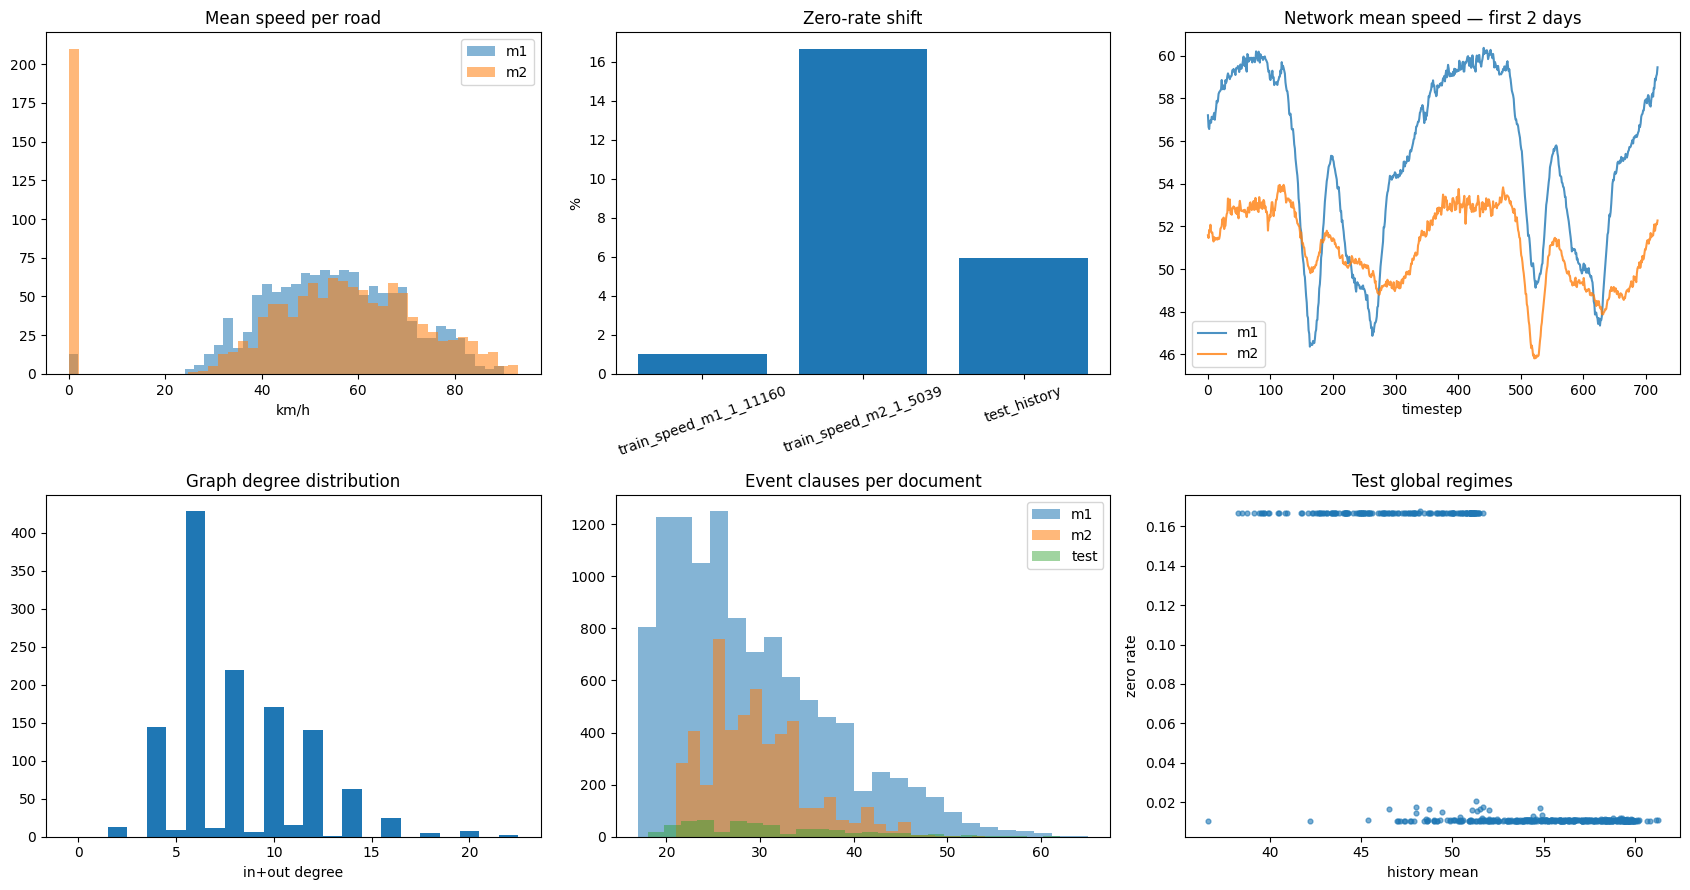

Graph nonzero incl diagonal: 5122 | degree min/median/max: 2 8.0 22
Text clauses median m1/m2/test: 27.0 28.0 29.0


In [2]:
def load_json_values(path):
    with Path(path).open() as f: return list(json.load(f).values())

speed_paths=sorted((DATA_DIR/'train').glob('train_speed_*.npy'))
text_paths=sorted((DATA_DIR/'train').glob('train_text_*.json'))
train_speeds=[np.load(p,mmap_mode='r') for p in speed_paths]
train_texts=[load_json_values(p) for p in text_paths]
test_hist=np.load(DATA_DIR/'test/test_X_hist.npy')
test_texts=load_json_values(DATA_DIR/'test/test_texts.json')
adjacency=np.load(DATA_DIR/'static/matrix.npy')
sample_submission=pd.read_csv(DATA_DIR/'sample_submission.csv')
assert [z.shape[1] for z in train_speeds]==[N_ROADS,N_ROADS]
assert test_hist.shape[1:]==(HISTORY,N_ROADS) and adjacency.shape==(N_ROADS,N_ROADS)

summary=pd.DataFrame([
    {'split':p.stem,'shape':str(z.shape),'mean':float(z.mean()),'std':float(z.std()),
     'zero_%':100*float(np.mean(z==0)),'min':float(z.min()),'max':float(z.max())}
    for p,z in zip(speed_paths,train_speeds)
]+[{'split':'test_history','shape':str(test_hist.shape),'mean':float(test_hist.mean()),
    'std':float(test_hist.std()),'zero_%':100*float(np.mean(test_hist==0)),
    'min':float(test_hist.min()),'max':float(test_hist.max())}])
display(summary.round(3))

src_all,dst_all=np.nonzero(adjacency!=0)
degree=np.bincount(np.r_[src_all,dst_all],minlength=N_ROADS)
doc_lengths=[[len([q for q in x.split('.') if q.strip()]) for x in block] for block in train_texts]
test_doc_lengths=[len([q for q in x.split('.') if q.strip()]) for x in test_texts]

fig,ax=plt.subplots(2,3,figsize=(17,9))
for z,label in zip(train_speeds,['m1','m2']): ax[0,0].hist(np.asarray(z).mean(0),bins=45,alpha=.55,label=label)
ax[0,0].set(title='Mean speed per road',xlabel='km/h'); ax[0,0].legend()
ax[0,1].bar(summary['split'],summary['zero_%']); ax[0,1].set(title='Zero-rate shift',ylabel='%'); ax[0,1].tick_params(axis='x',rotation=20)
for z,label in zip(train_speeds,['m1','m2']): ax[0,2].plot(np.asarray(z[:720]).mean(1),label=label,alpha=.8)
ax[0,2].set(title='Network mean speed — first 2 days',xlabel='timestep'); ax[0,2].legend()
ax[1,0].hist(degree,bins=np.arange(degree.max()+2)-.5); ax[1,0].set(title='Graph degree distribution',xlabel='in+out degree')
ax[1,1].hist(doc_lengths[0],bins=25,alpha=.55,label='m1'); ax[1,1].hist(doc_lengths[1],bins=25,alpha=.55,label='m2'); ax[1,1].hist(test_doc_lengths,bins=25,alpha=.45,label='test')
ax[1,1].set(title='Event clauses per document'); ax[1,1].legend()
test_global_mean=test_hist.mean((1,2)); test_zero=(test_hist==0).mean((1,2))
ax[1,2].scatter(test_global_mean,test_zero,s=12,alpha=.6); ax[1,2].set(title='Test global regimes',xlabel='history mean',ylabel='zero rate')
plt.tight_layout(); plt.show()
print('Graph nonzero incl diagonal:',int(np.count_nonzero(adjacency)),'| degree min/median/max:',int(degree.min()),float(np.median(degree)),int(degree.max()))
print('Text clauses median m1/m2/test:',np.median(doc_lengths[0]),np.median(doc_lengths[1]),np.median(test_doc_lengths))


### EDA interpretation

- m2 memiliki zero-rate jauh lebih tinggi daripada m1; nol dipertahankan dan diberikan sebagai mask, bukan diimputasi buta.
- Graph sparse dan directed; incoming/outgoing aggregation dipisahkan.
- Test terlihat sebagai dua cluster global. Kita ukur ini secara eksplisit di bagian regime.
- Recent-history smoothing tetap menjadi base forecast karena linear trend sebelumnya mudah meledak pada metric MSE.


## 3. Purged randomized-day validation

Hari dibagi deterministically ke lima kelompok; satu kelompok menjadi validation dan seluruh window yang menyentuh boundary dipurge. Protocol ini mengikuti notebook Malfa public 37.1 dan jauh lebih representative daripada easy-tail V3. Score utama tetap `test_weighted` 68.9/31.1.


In [3]:
DAY_LEN = 360        # 1 hari = 360 timestep (asumsi step 4 menit -> 24*60/4 = 360)
N_FOLDS = 5
PURGE = 15
HOLDOUT_FOLD = 0      # fold yang jadi validation tunggal untuk diagnostic run ini

def valid_times(n,start,stop,stride=1):
    return np.arange(max(HISTORY-1,start),min(stop,n-max(HORIZONS)),stride,dtype=np.int32)

def build_day_fold_seq(z_len, day_len=DAY_LEN, n_folds=N_FOLDS, seed=BASE_SEED):
    n_days = int(np.ceil(z_len / day_len))
    rng = np.random.default_rng(seed)
    order = np.arange(n_days); rng.shuffle(order)
    fold_of_day = np.empty(n_days, dtype=np.int32)
    for i, d in enumerate(order):
        fold_of_day[d] = i % n_folds
    fold_seq = fold_of_day[np.arange(z_len) // day_len]
    return fold_of_day, fold_seq

def split_purged_day_block(z_len, fold_seq, holdout_fold=HOLDOUT_FOLD, purge=PURGE):
    all_t = valid_times(z_len, HISTORY-1, z_len, 1)
    max_h = max(HORIZONS)
    train_list, val_list = [], []
    for t in all_t:
        core_lo, core_hi = t - HISTORY + 1, t + max_h
        buf_lo, buf_hi = max(0, core_lo - purge), min(z_len - 1, core_hi + purge)
        core = fold_seq[core_lo:core_hi + 1]
        buf = fold_seq[buf_lo:buf_hi + 1]
        if np.all(core == holdout_fold):
            val_list.append(t)
        elif not np.any(buf == holdout_fold):
            train_list.append(t)
        # else: zona purge -> dibuang, tidak dipakai train maupun val
    return np.asarray(train_list, dtype=np.int32), np.asarray(val_list, dtype=np.int32)

fold_maps = []; train_full_times = []; val_times = []
for z in train_speeds:
    fold_of_day, fold_seq = build_day_fold_seq(len(z))
    fold_maps.append(fold_of_day)
    tr, va = split_purged_day_block(len(z), fold_seq)
    train_full_times.append(tr); val_times.append(va)

experiment_times = [t[::EXPERIMENT_STRIDE] for t in train_full_times]
final_train_times = [t[::FINAL_STRIDE] for t in train_full_times]

# boolean row-mask per block (dipakai CELL 11 untuk fit PCA supaya tidak menyentuh hari held-out)
train_row_mask = [fold_of_day[np.arange(len(z)) // DAY_LEN] != HOLDOUT_FOLD
                   for z, fold_of_day in zip(train_speeds, fold_maps)]

if FAST_MODE:
    experiment_times=[t[-min(80,len(t)):] for t in experiment_times]
    final_train_times=[t[-min(100,len(t)):] for t in final_train_times]
    val_times=[t[-min(24,len(t)):] for t in val_times]

def collect_histories_targets(times_by_block,desc='collect windows'):
    hist=[]; targets=[]
    total=sum(len(x) for x in times_by_block)
    with tqdm(total=total,desc=desc,leave=False) as bar:
        for z,times in zip(train_speeds,times_by_block):
            for t in times:
                hist.append(np.asarray(z[t-HISTORY+1:t+1],dtype=np.float32))
                targets.append(np.stack([z[t+h] for h in HORIZONS],axis=-1).astype(np.float32)); bar.update()
    return np.stack(hist),np.stack(targets)

val_hist,val_y=collect_histories_targets(val_times,'validation windows')
VAL_LENGTHS=[len(x) for x in val_times]
print('Hari per fold tiap block:',[np.bincount(fm, minlength=N_FOLDS).tolist() for fm in fold_maps])
print('Experiment train:',[len(x) for x in experiment_times])
print('Final stride-1 train:',[len(x) for x in final_train_times])
print('Validation (purged day-block, holdout fold=%d):'%HOLDOUT_FOLD,VAL_LENGTHS,val_hist.shape,val_y.shape)

def horizon_mse(y,pred): return np.array([np.mean((y[...,i]-pred[...,i])**2) for i in range(3)])
def block_horizon_mse(y,pred,lengths=VAL_LENGTHS):
    cut=lengths[0]
    return np.stack([horizon_mse(y[:cut],pred[:cut]),horizon_mse(y[cut:cut+lengths[1]],pred[cut:cut+lengths[1]])])

Hari per fold tiap block: [[7, 6, 6, 6, 6], [3, 3, 3, 3, 2]]
Experiment train: [4151, 1877]
Final stride-1 train: [8301, 3753]
Validation (purged day-block, holdout fold=0): [2346, 993] (3339, 15, 1260) (3339, 1260, 3)


## 4. Reverse engineering regime

Fitur regime hanya memakai history yang tersedia: mean, standard deviation, dan zero-rate lintas 1.260 road untuk masing-masing 15 lag (45 fitur). Logistic regression bukan model target speed; ia hanya menghasilkan probabilitas konteks m2-like. Jika probabilitas test tidak jelas, soft gating akan tetap interpolate—berbeda dari hard expert.


,val_accuracy,val_auc,val_logloss,test_m1_like,test_m2_like,test_m1_weight,test_m2_weight
0,1.0,1.0,0.000321,372,168,0.688896,0.311104


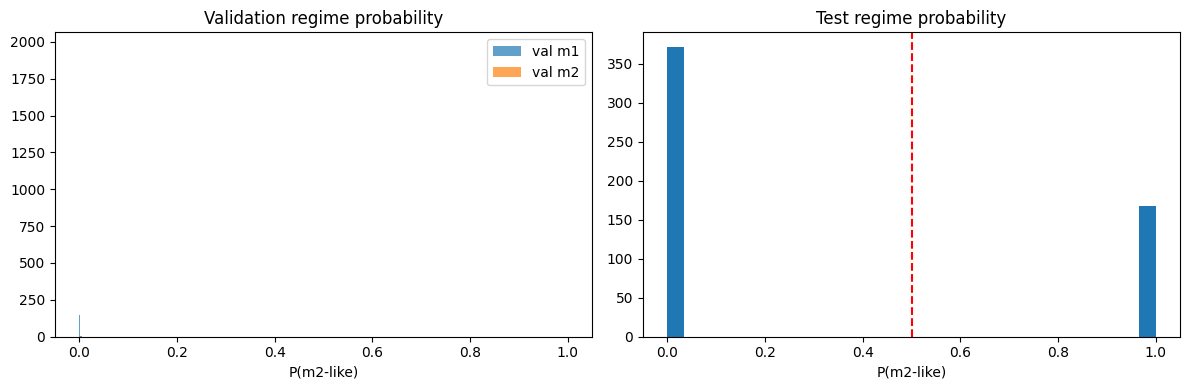

Inferred test block weights: {'m1': np.float64(0.688896), 'm2': np.float64(0.311104)}


In [4]:
def global_features_from_histories(histories,batch=128,desc='global features'):
    out=[]
    for start in tqdm(range(0,len(histories),batch),desc=desc,leave=False):
        x=np.asarray(histories[start:start+batch],dtype=np.float32)
        out.append(np.concatenate([x.mean(2),x.std(2),(x==0).mean(2)],axis=1).astype(np.float32))
    return np.concatenate(out)

def global_features_for_times(times_by_block,batch=128,desc='train global features'):
    out=[]; labels=[]
    total=sum((len(t)+batch-1)//batch for t in times_by_block)
    with tqdm(total=total,desc=desc,leave=False) as bar:
        for b,(z,times) in enumerate(zip(train_speeds,times_by_block)):
            parts=[]
            for start in range(0,len(times),batch):
                ts=times[start:start+batch]
                w=np.stack([z[t-HISTORY+1:t+1] for t in ts]).astype(np.float32)
                parts.append(np.concatenate([w.mean(2),w.std(2),(w==0).mean(2)],axis=1)); bar.update()
            out.append(np.concatenate(parts)); labels.extend([b]*len(times))
    return np.concatenate(out).astype(np.float32),np.asarray(labels)

global_train,regime_train_y=global_features_for_times(experiment_times)
global_val=global_features_from_histories(val_hist,desc='validation regime features')
global_test=global_features_from_histories(test_hist,desc='test regime features')
global_scaler=StandardScaler().fit(global_train)
regime_clf=LogisticRegression(C=.1,max_iter=1000,random_state=BASE_SEED).fit(global_scaler.transform(global_train),regime_train_y)
val_regime_y=np.r_[np.zeros(VAL_LENGTHS[0],dtype=int),np.ones(VAL_LENGTHS[1],dtype=int)]
val_regime_p=regime_clf.predict_proba(global_scaler.transform(global_val))[:,1]
test_regime_p=regime_clf.predict_proba(global_scaler.transform(global_test))[:,1]
TEST_BLOCK_WEIGHTS=np.array([np.mean(1-test_regime_p),np.mean(test_regime_p)])

regime_report=pd.DataFrame([{
    'val_accuracy':accuracy_score(val_regime_y,val_regime_p>=.5),
    'val_auc':roc_auc_score(val_regime_y,val_regime_p),
    'val_logloss':log_loss(val_regime_y,val_regime_p),
    'test_m1_like':int(np.sum(test_regime_p<.5)),'test_m2_like':int(np.sum(test_regime_p>=.5)),
    'test_m1_weight':TEST_BLOCK_WEIGHTS[0],'test_m2_weight':TEST_BLOCK_WEIGHTS[1]}])
display(regime_report.round(6))
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].hist(val_regime_p[:VAL_LENGTHS[0]],bins=20,alpha=.7,label='val m1'); ax[0].hist(val_regime_p[VAL_LENGTHS[0]:],bins=20,alpha=.7,label='val m2'); ax[0].set(title='Validation regime probability',xlabel='P(m2-like)'); ax[0].legend()
ax[1].hist(test_regime_p,bins=30); ax[1].axvline(.5,color='red',ls='--'); ax[1].set(title='Test regime probability',xlabel='P(m2-like)')
plt.tight_layout(); plt.show()
print('Inferred test block weights:',dict(zip(['m1','m2'],TEST_BLOCK_WEIGHTS.round(6))))


## 5. Strong non-neural anchors: AR dan PCA residual

Shared AR memodelkan perubahan dari latest speed dan menjadi anchor konservatif. PCA residual menangkap city-wide low-rank state yang tidak mudah ditangkap per-road AR. Eksperimen manual KNN analog, per-road graph ridge, dan LightGBM residual lebih buruk (38.59, 29.55, dan 30.06), sehingga tidak membebani notebook final.


PCA ridge horizons: 100%|██████████| 3/3 [00:01<00:00,  2.05it/s]


,model,h5,h10,h15,mean
0,AR,36.47958,45.401112,52.653759,44.844818
1,PCA,33.45290,38.060959,40.857079,37.456982


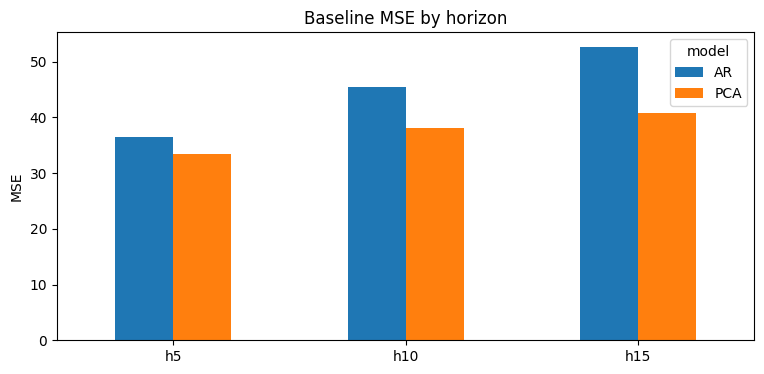

Direct low-rank MSE per horizon / mean: [30.64591 32.7328  34.62707] 32.6685905456543


In [5]:
def fit_shared_ar(times_by_block,max_timestamps_per_block=1400,alpha=1000.,seed=BASE_SEED):
    rng=np.random.default_rng(seed); xs=[]; ys={h:[] for h in HORIZONS}
    for z,times in zip(train_speeds,times_by_block):
        take=min(len(times),max_timestamps_per_block if not FAST_MODE else 40)
        chosen=np.sort(rng.choice(times,size=take,replace=False))
        w=np.stack([z[t-HISTORY+1:t+1] for t in chosen]).astype(np.float32)
        xs.append((w-w[:,-1:]).transpose(0,2,1).reshape(-1,HISTORY))
        for h in HORIZONS: ys[h].append((z[chosen+h]-z[chosen]).reshape(-1).astype(np.float32))
    X=np.concatenate(xs); return {h:Ridge(alpha=alpha).fit(X,np.concatenate(ys[h])) for h in HORIZONS}

def predict_ar_histories(models,histories,batch=256,desc=None):
    out=[]; iterator=range(0,len(histories),batch)
    if desc: iterator=tqdm(iterator,desc=desc,leave=False)
    for start in iterator:
        w=np.asarray(histories[start:start+batch],dtype=np.float32)
        x=(w-w[:,-1:]).transpose(0,2,1).reshape(-1,HISTORY); latest=w[:,-1].reshape(-1)
        out.append(np.stack([(latest+models[h].predict(x)).reshape(len(w),N_ROADS) for h in HORIZONS],axis=-1))
    return np.concatenate(out).astype(np.float32)

ar_val_models=fit_shared_ar(experiment_times)
val_pred_ar=predict_ar_histories(ar_val_models,val_hist,desc='AR validation')

def fit_road_pca(row_masks,n_components=PCA_DIM):
    rows=np.concatenate([np.asarray(z,dtype=np.float32)[mask] for z,mask in zip(train_speeds,row_masks)])
    model=PCA(n_components=n_components,whiten=True,svd_solver='randomized',random_state=BASE_SEED).fit(rows)
    del rows; gc.collect(); return model
def summary_from_windows(w):
    return np.stack([w[:,0:3].mean(1),w[:,5:8].mean(1),w[:,10:13].mean(1),w[:,-3:].mean(1),w[:,-1]-w[:,-5]],axis=1)
def pca_features_hist(pca,histories,batch=128,desc='PCA features'):
    out=[]
    for start in tqdm(range(0,len(histories),batch),desc=desc,leave=False):
        s=summary_from_windows(np.asarray(histories[start:start+batch],dtype=np.float32))
        out.append(np.concatenate([pca.transform(s[:,k]) for k in range(5)],axis=1))
    return np.concatenate(out).astype(np.float32)
def pca_features_times(pca,times_by_block,batch=128):
    out=[]
    for z,times in zip(train_speeds,times_by_block):
        for start in tqdm(range(0,len(times),batch),desc='PCA train block',leave=False):
            ts=times[start:start+batch]; w=np.stack([z[t-HISTORY+1:t+1] for t in ts]).astype(np.float32)
            s=summary_from_windows(w); out.append(np.concatenate([pca.transform(s[:,k]) for k in range(5)],axis=1))
    return np.concatenate(out).astype(np.float32)
def targets_bases(times_by_block,ar_models,batch=128):
    yy=[]; bb=[]
    for z,times in zip(train_speeds,times_by_block):
        for start in tqdm(range(0,len(times),batch),desc='PCA targets',leave=False):
            ts=times[start:start+batch]; w=np.stack([z[t-HISTORY+1:t+1] for t in ts]).astype(np.float32)
            yy.append(np.stack([z[ts+h] for h in HORIZONS],axis=-1)); bb.append(predict_ar_histories(ar_models,w))
    return np.concatenate(yy).astype(np.float32),np.concatenate(bb).astype(np.float32)

pca_val=fit_road_pca(train_row_mask); Fp_train=pca_features_times(pca_val,experiment_times); Fp_val=pca_features_hist(pca_val,val_hist)
Yp,Bp=targets_bases(experiment_times,ar_val_models)
pca_alphas=[1e2,1e4,1e5] if not FAST_MODE else [1e4]
pca_models={}; pca_best_alpha={}; pca_parts=[]
for i,h in enumerate(tqdm(HORIZONS,desc='PCA ridge horizons')):
    best=(float('inf'),None,None,None); residual=Yp[...,i]-Bp[...,i]
    for alpha in pca_alphas:
        m=Ridge(alpha=alpha).fit(Fp_train,residual); pred=val_pred_ar[...,i]+m.predict(Fp_val)
        score=np.mean((val_y[...,i]-pred)**2)
        if score<best[0]: best=(score,alpha,m,pred.astype(np.float32))
    _,pca_best_alpha[h],pca_models[h],pred=best; pca_parts.append(pred)
val_pred_pca=np.stack(pca_parts,axis=-1); del Yp,Bp; gc.collect()
baseline=pd.DataFrame({'model':['AR','PCA'],'h5':[horizon_mse(val_y,val_pred_ar)[0],horizon_mse(val_y,val_pred_pca)[0]],
                       'h10':[horizon_mse(val_y,val_pred_ar)[1],horizon_mse(val_y,val_pred_pca)[1]],
                       'h15':[horizon_mse(val_y,val_pred_ar)[2],horizon_mse(val_y,val_pred_pca)[2]]})
baseline['mean']=baseline[['h5','h10','h15']].mean(1); display(baseline.round(5))
baseline.set_index('model')[['h5','h10','h15']].T.plot(kind='bar',figsize=(9,4),title='Baseline MSE by horizon'); plt.ylabel('MSE'); plt.xticks(rotation=0); plt.show()


# V5 rapid component: Raphael-inspired direct city-state forecast.
class DirectLowRank:
    def __init__(self,k=64,alpha=100.0): self.k,self.alpha=k,alpha
    def fit(self,times_by_block,row_masks):
        rows=np.concatenate([np.asarray(z,dtype=np.float32)[mask] for z,mask in zip(train_speeds,row_masks)])
        self.pca=PCA(n_components=self.k,whiten=True,svd_solver='randomized',random_state=BASE_SEED).fit(rows)
        self.lo=np.quantile(rows,.005,axis=0).astype(np.float32); self.hi=np.quantile(rows,.995,axis=0).astype(np.float32)
        del rows; gc.collect()
        zblocks=[self.pca.transform(np.asarray(z,dtype=np.float32)).astype(np.float32) for z in train_speeds]
        X=[]; Y=[]
        for zlat,times in zip(zblocks,times_by_block):
            X.append(np.stack([zlat[t-HISTORY+1:t+1].reshape(-1) for t in tqdm(times,desc='direct LR histories',leave=False)]))
            Y.append(np.stack([np.concatenate([zlat[t+h] for h in HORIZONS]) for t in times]))
        X=np.concatenate(X).astype(np.float32); Y=np.concatenate(Y).astype(np.float32)
        self.model=Ridge(alpha=self.alpha).fit(X,Y); del X,Y,zblocks; gc.collect(); return self
    def predict(self,histories,batch=96,desc='direct low-rank inference'):
        out=[]
        for start in tqdm(range(0,len(histories),batch),desc=desc,leave=False):
            w=np.asarray(histories[start:start+batch],dtype=np.float32); z=self.pca.transform(w.reshape(-1,N_ROADS)).reshape(len(w),HISTORY,self.k)
            predz=self.model.predict(z.reshape(len(w),-1)).reshape(len(w),3,self.k)
            pred=np.stack([self.pca.inverse_transform(predz[:,i]) for i in range(3)],axis=-1)
            out.append(np.clip(pred,self.lo[None,:,None],self.hi[None,:,None]).astype(np.float32))
        return np.concatenate(out)

DIRECT_K=64 if not FAST_MODE else 8
direct_lr_val_model=DirectLowRank(DIRECT_K,100.0).fit(final_train_times,train_row_mask)
val_pred_direct_lr=direct_lr_val_model.predict(val_hist,desc='direct low-rank validation')
direct_lr_mse=horizon_mse(val_y,val_pred_direct_lr)
print('Direct low-rank MSE per horizon / mean:',np.round(direct_lr_mse,5),float(direct_lr_mse.mean()))


## 6. Text preprocessing

Event text semi-terstruktur dan test mengandung kombinasi clause yang tidak selalu pernah terlihat verbatim. Word 1–3 gram TF-IDF dapat berbagi kata event/lokasi, lalu SVD memadatkannya agar road-specific gate tetap ringan.


In [6]:
all_train_text=[s for block in train_texts for s in block]
tfidf=TfidfVectorizer(ngram_range=(1,3),min_df=3,max_features=7000,sublinear_tf=True,dtype=np.float32)
text_sparse=tfidf.fit_transform(all_train_text)
text_dim_actual=min(TEXT_DIM,text_sparse.shape[1]-1)
text_svd=TruncatedSVD(n_components=text_dim_actual,n_iter=7,random_state=BASE_SEED)
all_text_z=text_svd.fit_transform(text_sparse).astype(np.float32)
test_text_z=text_svd.transform(tfidf.transform(test_texts)).astype(np.float32)
offsets=np.cumsum([0]+[len(x) for x in train_texts])
train_text_z=[all_text_z[offsets[i]:offsets[i+1]] for i in range(2)]
print('TF-IDF:',text_sparse.shape,'latent:',all_text_z.shape,'explained variance:',float(text_svd.explained_variance_ratio_.sum()))
del text_sparse,all_text_z; gc.collect()


TF-IDF: (16199, 2021) latent: (16199, 32) explained variance: 0.6661109924316406


0

## 7. Neural family: directed graph + text gate + global FiLM

Semua model memprediksi residual dari mean tiga speed terakhir. FiLM mengubah hidden representation road berdasarkan global trajectory dan regime probability. EMA adalah weight averaging, sedangkan soft-MoE mencampur dua output head menggunakan probabilitas regime. Ablation menjaga komponen lain sama agar kesimpulan kausal lebih masuk akal.


In [7]:
src_np,dst_np=np.nonzero(adjacency!=0); keep=src_np!=dst_np; src_np,dst_np=src_np[keep],dst_np[keep]
out_degree_np=np.bincount(src_np,minlength=N_ROADS).clip(min=1).astype(np.float32)
in_degree_np=np.bincount(dst_np,minlength=N_ROADS).clip(min=1).astype(np.float32)
norm_rows=np.concatenate([np.asarray(z,dtype=np.float32)[mask] for z,mask in zip(train_speeds,train_row_mask)])
road_mean=norm_rows.mean(0).astype(np.float32); road_std=(norm_rows.std(0)+3.).astype(np.float32); del norm_rows; gc.collect()

class TrafficDataset(Dataset):
    def __init__(self,times_by_block): self.index=[(b,int(t)) for b,times in enumerate(times_by_block) for t in times]
    def __len__(self): return len(self.index)
    def __getitem__(self,i):
        b,t=self.index[i]; z=train_speeds[b]
        hist=np.asarray(z[t-HISTORY+1:t+1],dtype=np.float32).T.copy()
        target=np.stack([z[t+h] for h in HORIZONS],axis=-1).astype(np.float32)
        return torch.from_numpy(hist),torch.from_numpy(train_text_z[b][t]),torch.from_numpy(target)

class DirectedGraphBlock(nn.Module):
    def __init__(self,hidden):
        super().__init__(); self.self_linear=nn.Linear(hidden,hidden); self.in_linear=nn.Linear(hidden,hidden,bias=False); self.out_linear=nn.Linear(hidden,hidden,bias=False); self.norm=nn.LayerNorm(hidden); self.dropout=nn.Dropout(.1)
    def forward(self,h,src,dst,in_degree,out_degree):
        incoming=torch.zeros_like(h); outgoing=torch.zeros_like(h)
        incoming.index_add_(1,dst,h[:,src]); outgoing.index_add_(1,src,h[:,dst])
        u=torch.nn.functional.gelu(self.self_linear(h)+self.in_linear(incoming/in_degree[None,:,None])+self.out_linear(outgoing/out_degree[None,:,None]))
        return self.norm(h+self.dropout(u))

@dataclass(frozen=True)
class ModelConfig:
    name:str; use_global:bool=False; use_ema:bool=False; use_moe:bool=False; zero_aux_weight:float=.1

class TrafficNetV3(nn.Module):
    def __init__(self,config,mean_np,std_np,global_scaler_local,regime_clf_local,hidden=HIDDEN_DIM):
        super().__init__(); self.config=config
        self.register_buffer('road_mean',torch.tensor(mean_np).view(1,N_ROADS,1)); self.register_buffer('road_std',torch.tensor(std_np).view(1,N_ROADS,1))
        self.register_buffer('src',torch.tensor(src_np,dtype=torch.long)); self.register_buffer('dst',torch.tensor(dst_np,dtype=torch.long)); self.register_buffer('in_degree',torch.tensor(in_degree_np)); self.register_buffer('out_degree',torch.tensor(out_degree_np))
        self.register_buffer('global_mean',torch.tensor(global_scaler_local.mean_,dtype=torch.float32)); self.register_buffer('global_scale',torch.tensor(global_scaler_local.scale_,dtype=torch.float32))
        raw_coef=regime_clf_local.coef_[0]/global_scaler_local.scale_; raw_intercept=regime_clf_local.intercept_[0]-np.sum(regime_clf_local.coef_[0]*global_scaler_local.mean_/global_scaler_local.scale_)
        self.register_buffer('regime_coef',torch.tensor(raw_coef,dtype=torch.float32)); self.register_buffer('regime_intercept',torch.tensor(raw_intercept,dtype=torch.float32))
        self.road_embedding=nn.Embedding(N_ROADS,12)
        self.history_encoder=nn.Sequential(nn.Linear(HISTORY*3+12,hidden),nn.GELU(),nn.Dropout(.1),nn.Linear(hidden,hidden),nn.GELU())
        gate_dim=16; self.text_context=nn.Sequential(nn.Linear(text_dim_actual,hidden),nn.GELU(),nn.Linear(hidden,hidden)); self.text_query=nn.Linear(text_dim_actual,gate_dim); self.road_event_embedding=nn.Embedding(N_ROADS,gate_dim)
        if config.use_global: self.film=nn.Sequential(nn.Linear(45+1+text_dim_actual,hidden),nn.GELU(),nn.Linear(hidden,hidden*2))
        self.graph_blocks=nn.ModuleList([DirectedGraphBlock(hidden),DirectedGraphBlock(hidden)])
        def make_heads(): return nn.ModuleList([nn.Sequential(nn.Linear(hidden,hidden//2),nn.GELU(),nn.Linear(hidden//2,1)) for _ in HORIZONS])
        self.heads_a=make_heads(); self.heads_b=make_heads() if config.use_moe else None; self.zero_head=nn.Linear(hidden,3)
        for heads in [self.heads_a,self.heads_b]:
            if heads is not None:
                for head in heads: nn.init.zeros_(head[-1].weight); nn.init.zeros_(head[-1].bias)
    def forward(self,hist,text):
        normalized=(hist-self.road_mean)/self.road_std; base=hist[:,:,-3:].mean(-1,keepdim=True); deviations=(hist-base)/self.road_std; zero=(hist==0).to(hist.dtype)
        ids=torch.arange(N_ROADS,device=hist.device); emb=self.road_embedding(ids)[None].expand(len(hist),-1,-1)
        h=self.history_encoder(torch.cat([normalized,deviations,zero,emb],-1))
        context=self.text_context(text)[:,None]; query=self.text_query(text); gate=torch.sigmoid(torch.einsum('bd,rd->br',query,self.road_event_embedding.weight)/(query.shape[-1]**.5)); h=h+gate[...,None]*context
        raw_global=torch.cat([hist.mean(1),hist.std(1,unbiased=False),(hist==0).to(hist.dtype).mean(1)],1)
        regime_p=torch.sigmoid(raw_global@self.regime_coef+self.regime_intercept)
        if self.config.use_global:
            gnorm=(raw_global-self.global_mean)/self.global_scale; gamma,beta=self.film(torch.cat([gnorm,regime_p[:,None],text],1)).chunk(2,1)
            h=h*(1+.15*torch.tanh(gamma[:,None]))+.15*beta[:,None]
        for block in self.graph_blocks: h=block(h,self.src,self.dst,self.in_degree,self.out_degree)
        ra=torch.cat([head(h) for head in self.heads_a],-1)
        if self.heads_b is not None:
            rb=torch.cat([head(h) for head in self.heads_b],-1); residual=(1-regime_p[:,None,None])*ra+regime_p[:,None,None]*rb
        else: residual=ra
        return base+residual*self.road_std,self.zero_head(h),regime_p

ABLATIONS=[ModelConfig('global_film_ema_soft_moe',use_global=True,use_ema=True,use_moe=True)]
display(pd.DataFrame([asdict(x) for x in ABLATIONS]))


,name,use_global,use_ema,use_moe,zero_aux_weight
0,global_film_ema_soft_moe,True,True,True,0.1


## 8. Training, ablation, dan evaluation diagnostics

Epoch, architecture, seed, dan inference loops memakai `tqdm`. Early stopping memilih test-weighted score, tetapi balanced dan block-specific MSE tetap tersimpan sebagai tulisan/CSV. EMA hanya dipakai pada config yang menyatakannya.


global_film_ema_soft_moe seed=42: 100%|██████████| 10/10 [01:07<00:00,  6.74s/it, balanced=32.056, train=33.935, weighted=34.514]
                                                                                                                                 
Architecture ablations: 100%|██████████| 1/1 [01:09<00:00, 69.77s/it]


,model,h5,h10,h15,balanced_mean,test_weighted_mean,m1_mean,m2_mean,best_epoch
0,global_film_ema_soft_moe,28.340281,32.382481,35.436859,32.0532,34.50009,38.530029,25.57638,9


Selected by inferred test-composition MSE: ModelConfig(name='global_film_ema_soft_moe', use_global=True, use_ema=True, use_moe=True, zero_aux_weight=0.1)


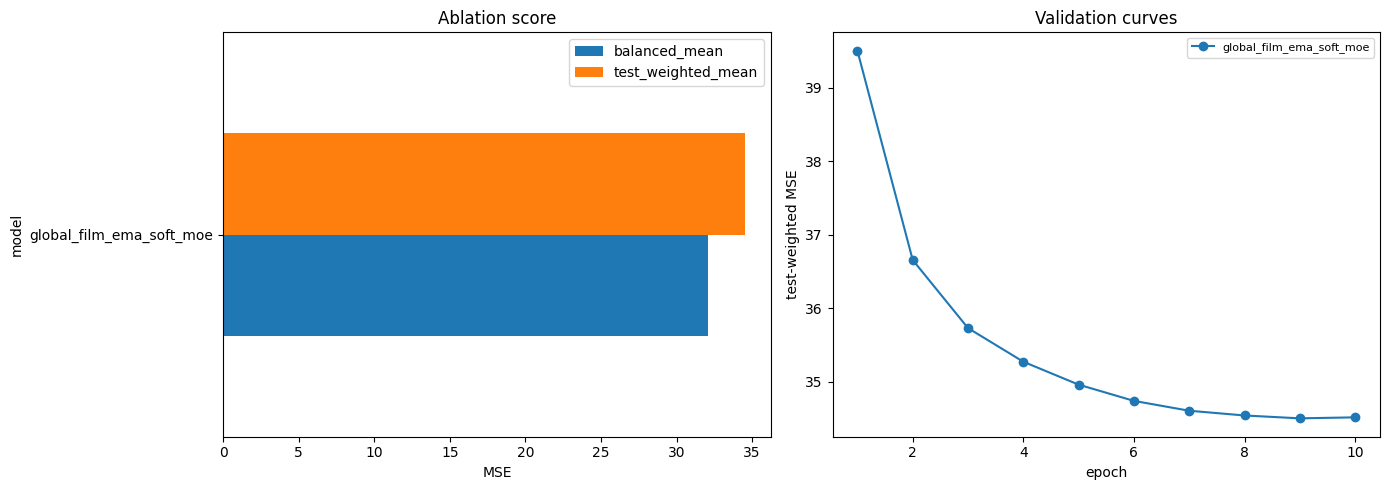

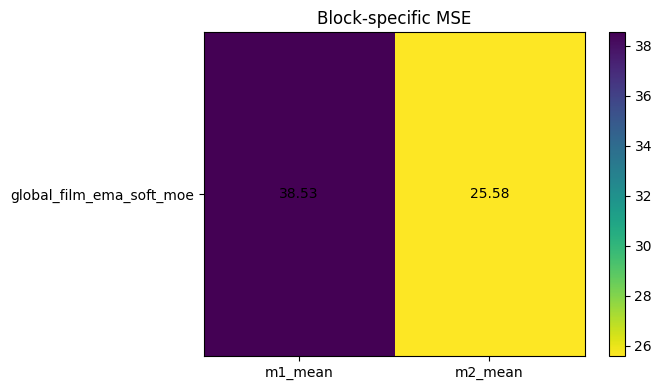

In [8]:
def make_loader(times,shuffle,seed,batch_size=BATCH_SIZE):
    g=torch.Generator(); g.manual_seed(seed)
    return DataLoader(TrafficDataset(times),batch_size=batch_size,shuffle=shuffle,num_workers=NUM_WORKERS,pin_memory=torch.cuda.is_available(),generator=g)

def evaluate_neural(model,loader,return_pred=False,desc=None):
    model.eval(); parts=[]
    with torch.no_grad():
        iterator=loader if desc is None else tqdm(loader,desc=desc,leave=False)
        for hist,text,target in iterator:
            pred,_,_=model(hist.to(DEVICE),text.to(DEVICE)); parts.append(pred.cpu().numpy())
    pred=np.concatenate(parts); scores=horizon_mse(val_y,pred) if len(pred)==len(val_y) else None
    return (scores,pred) if return_pred else scores

def score_details(y,pred):
    blocks=block_horizon_mse(y,pred); balanced=blocks.mean(0); weighted=TEST_BLOCK_WEIGHTS@blocks
    return blocks,balanced,weighted

@torch.no_grad()
def ema_update(ema_model,model,decay=.995):
    for ep,p in zip(ema_model.parameters(),model.parameters()): ep.mul_(decay).add_(p,alpha=1-decay)
    for eb,b in zip(ema_model.buffers(),model.buffers()): eb.copy_(b)

def train_neural(config,train_times_local,val_times_local,mean_np,std_np,scaler_local,clf_local,seed,epochs):
    set_seed(seed); train_loader=make_loader(train_times_local,True,seed); val_loader=make_loader(val_times_local,False,seed) if val_times_local is not None else None
    model=TrafficNetV3(config,mean_np,std_np,scaler_local,clf_local).to(DEVICE); ema_model=copy.deepcopy(model).eval() if config.use_ema else None
    optimizer=torch.optim.AdamW(model.parameters(),lr=2e-3,weight_decay=1e-4); scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=max(1,epochs)); pos_weight=torch.tensor(5.,device=DEVICE)
    best_state=None; best=float('inf'); best_epoch=0; stale=0; logs=[]
    bar=trange(1,epochs+1,desc=f'{config.name} seed={seed}',leave=False)
    for epoch in bar:
        model.train(); train_sse=0.; train_n=0; started=time.time()
        for hist,text,target in train_loader:
            hist,text,target=hist.to(DEVICE),text.to(DEVICE),target.to(DEVICE); optimizer.zero_grad(set_to_none=True)
            pred,zero_logits,_=model(hist,text); mse=((pred-target)**2).mean(); loss=mse
            if config.zero_aux_weight: loss=loss+config.zero_aux_weight*torch.nn.functional.binary_cross_entropy_with_logits(zero_logits,(target==0).to(target.dtype),pos_weight=pos_weight)
            loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(),5.); optimizer.step()
            if ema_model is not None: ema_update(ema_model,model)
            train_sse+=mse.item()*target.numel(); train_n+=target.numel()
        scheduler.step(); chosen=ema_model if ema_model is not None else model; train_mse=train_sse/train_n
        if val_loader is not None:
            _,pred=evaluate_neural(chosen,val_loader,True); blocks,balanced,weighted=score_details(val_y,pred); select=float(weighted.mean())
        else: balanced=weighted=np.repeat(train_mse,3); select=train_mse
        logs.append({'epoch':epoch,'train_mse':train_mse,'balanced_mse':float(np.mean(balanced)),'test_weighted_mse':float(np.mean(weighted)),'seconds':time.time()-started})
        bar.set_postfix(train=f'{train_mse:.3f}',balanced=f'{np.mean(balanced):.3f}',weighted=f'{np.mean(weighted):.3f}')
        if select<best-1e-4:
            best=select; best_epoch=epoch; stale=0; best_state={k:v.detach().cpu().clone() for k,v in chosen.state_dict().items()}
        else:
            stale+=1
            if val_loader is not None and stale>=PATIENCE: break
    model.load_state_dict(best_state); return model,pd.DataFrame(logs),best_epoch,best

val_loader_fixed=make_loader(val_times,False,BASE_SEED)
ablation_rows=[]; ablation_predictions={}; ablation_logs={}; ablation_epochs={}
for config in tqdm(ABLATIONS,desc='Architecture ablations'):
    model,log,best_epoch,best=train_neural(config,experiment_times,val_times,road_mean,road_std,global_scaler,regime_clf,BASE_SEED,EXPERIMENT_EPOCHS)
    _,pred=evaluate_neural(model,val_loader_fixed,True,desc=f'evaluate {config.name}'); blocks,balanced,weighted=score_details(val_y,pred)
    ablation_predictions[config.name]=pred.astype(np.float32); ablation_logs[config.name]=log; ablation_epochs[config.name]=best_epoch
    ablation_rows.append({'model':config.name,'h5':balanced[0],'h10':balanced[1],'h15':balanced[2],'balanced_mean':balanced.mean(),'test_weighted_mean':weighted.mean(),'m1_mean':blocks[0].mean(),'m2_mean':blocks[1].mean(),'best_epoch':best_epoch})
    del model; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

ablation_report=pd.DataFrame(ablation_rows).sort_values('test_weighted_mean').reset_index(drop=True); display(ablation_report.round(5))
best_name=ablation_report.iloc[0].model; best_config=next(c for c in ABLATIONS if c.name==best_name)
print('Selected by inferred test-composition MSE:',best_config)

fig,ax=plt.subplots(1,2,figsize=(14,5))
ablation_report.sort_values('test_weighted_mean').plot.barh(x='model',y=['balanced_mean','test_weighted_mean'],ax=ax[0]); ax[0].set(title='Ablation score',xlabel='MSE')
for name,log in ablation_logs.items(): ax[1].plot(log.epoch,log.test_weighted_mse,marker='o',label=name)
ax[1].set(title='Validation curves',xlabel='epoch',ylabel='test-weighted MSE'); ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

heat=ablation_report.set_index('model')[['m1_mean','m2_mean']]
fig,ax=plt.subplots(figsize=(7,4)); im=ax.imshow(heat.values,aspect='auto',cmap='viridis_r'); ax.set_xticks(range(2),heat.columns); ax.set_yticks(range(len(heat)),heat.index)
for i in range(len(heat)):
    for j in range(2): ax.text(j,i,f'{heat.iloc[i,j]:.2f}',ha='center',va='center')
ax.set_title('Block-specific MSE'); plt.colorbar(im,ax=ax); plt.tight_layout(); plt.show()


## 9. Stride-1 multi-seed confirmation

Architecture search memakai stride 2 untuk efisiensi. Kandidat terbaik kemudian diuji ulang pada stride 1 dan tiga seed. Kita memilih median best epoch untuk full refit; seed averaging mengurangi variance tanpa mengintip test target.


global_film_ema_soft_moe seed=42:  92%|█████████▏| 11/12 [02:23<00:11, 11.93s/it, balanced=31.414, train=32.139, weighted=33.872]
                                                                                                                                 
global_film_ema_soft_moe seed=2026:  67%|██████▋   | 8/12 [01:47<00:47, 11.94s/it, balanced=31.479, train=32.273, weighted=33.909]
                                                                                                                                  
Stride-1 seed confirmation: 100%|██████████| 2/2 [04:14<00:00, 127.15s/it]


,seed,h5,h10,h15,balanced_mean,test_weighted_mean,best_epoch
0,42,27.88938,31.68450,34.581089,31.384991,33.82163,9
1,2026,27.95454,31.77388,34.643902,31.457439,33.83098,6


Seed-average balanced: [27.74853 31.4545  34.2498 ] mean 31.150946
Seed-average test-weighted: [29.56564 33.89484 37.09685] mean 33.51911153466626 | refit epochs: 7


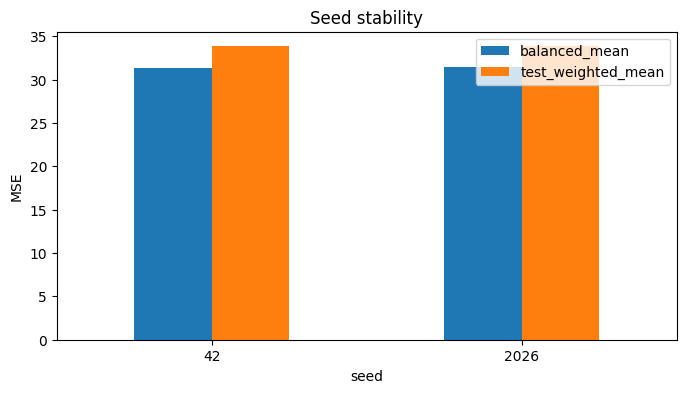

In [9]:
seed_predictions=[]; seed_rows=[]; seed_epochs=[]
for seed in tqdm(SEEDS,desc='Stride-1 seed confirmation'):
    model,log,best_epoch,best=train_neural(best_config,final_train_times,val_times,road_mean,road_std,global_scaler,regime_clf,seed,SEED_SEARCH_EPOCHS)
    _,pred=evaluate_neural(model,val_loader_fixed,True,desc=f'seed {seed} validation'); blocks,balanced,weighted=score_details(val_y,pred)
    seed_predictions.append(pred.astype(np.float32)); seed_epochs.append(best_epoch)
    seed_rows.append({'seed':seed,'h5':balanced[0],'h10':balanced[1],'h15':balanced[2],'balanced_mean':balanced.mean(),'test_weighted_mean':weighted.mean(),'best_epoch':best_epoch})
    del model; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
seed_report=pd.DataFrame(seed_rows); display(seed_report.round(5))
val_pred_gnn=np.mean(seed_predictions,axis=0).astype(np.float32); gnn_blocks,gnn_balanced,gnn_weighted=score_details(val_y,val_pred_gnn)
refit_epochs=max(1,int(np.median(seed_epochs)))
print('Seed-average balanced:',gnn_balanced.round(5),'mean',gnn_balanced.mean())
print('Seed-average test-weighted:',gnn_weighted.round(5),'mean',gnn_weighted.mean(),'| refit epochs:',refit_epochs)
seed_report.set_index('seed')[['balanced_mean','test_weighted_mean']].plot(kind='bar',figsize=(8,4),title='Seed stability'); plt.ylabel('MSE'); plt.xticks(rotation=0); plt.show()


## 10. Test-weighted non-negative ensemble

AR, PCA, dan neural memiliki error pattern berbeda. Bobot simplex non-negatif dipelajari per horizon dengan sample weights 69/31 hasil regime inference. Constraint mencegah extrapolative weight yang berbahaya untuk MSE. Balanced score tetap dihitung sebagai audit.


,horizon,w_AR,w_PCA,w_DirectLR,w_GNN,balanced_MSE,test_weighted_MSE
0,h5,0.0,0.130822,0.402849,0.466328,26.598773,28.332140
1,h10,0.0,0.117131,0.546155,0.336713,29.180407,31.350108
2,h15,0.0,0.111376,0.595554,0.293070,31.017640,33.409188


V5 balanced mean: 28.932275772094727 | V2 balanced reference: 27.426926
V5 inferred-test-weighted mean: 31.03048388813345


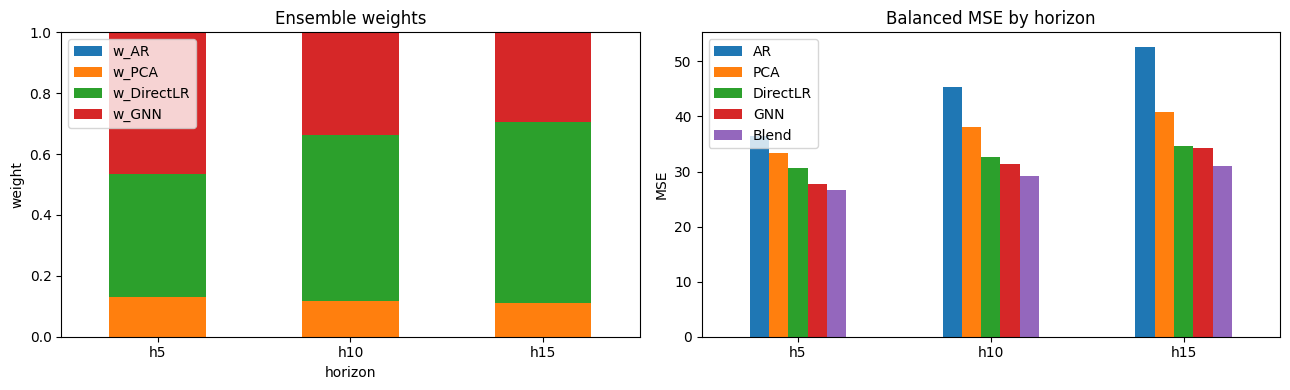

In [10]:
model_names=['AR','PCA','DirectLR','GNN']; val_candidates=[val_pred_ar,val_pred_pca,val_pred_direct_lr,val_pred_gnn]
def simplex_weights_weighted(y,preds):
    X=np.stack([p.reshape(-1).astype(np.float64) for p in preds],1); yy=y.reshape(-1).astype(np.float64)
    sample_w=np.r_[np.repeat(TEST_BLOCK_WEIGHTS[0]/VAL_LENGTHS[0],VAL_LENGTHS[0]),np.repeat(TEST_BLOCK_WEIGHTS[1]/VAL_LENGTHS[1],VAL_LENGTHS[1])]
    w=np.repeat(sample_w,N_ROADS); w=w/w.sum(); G=X.T@(X*w[:,None]); c=X.T@(yy*w)
    fun=lambda a:float(a@G@a-2*c@a); jac=lambda a:2*G@a-2*c
    result=minimize(fun,np.full(len(preds),1/len(preds)),jac=jac,bounds=[(0,1)]*len(preds),constraints={'type':'eq','fun':lambda a:a.sum()-1},method='SLSQP',options={'ftol':1e-12,'maxiter':200})
    assert result.success,result.message; return result.x

blend_weights=[]; blend_parts=[]; blend_rows=[]
for i,h in enumerate(HORIZONS):
    w=simplex_weights_weighted(val_y[...,i],[p[...,i] for p in val_candidates]); pred=sum(w[j]*val_candidates[j][...,i] for j in range(len(w)))
    blend_weights.append(w); blend_parts.append(pred.astype(np.float32)); cut=VAL_LENGTHS[0]
    blocks=np.array([np.mean((val_y[:cut,:,i]-pred[:cut])**2),np.mean((val_y[cut:cut+VAL_LENGTHS[1],:,i]-pred[cut:cut+VAL_LENGTHS[1]])**2)])
    blend_rows.append({'horizon':f'h{h}',**{f'w_{n}':w[j] for j,n in enumerate(model_names)},'balanced_MSE':blocks.mean(),'test_weighted_MSE':TEST_BLOCK_WEIGHTS@blocks})
val_pred_blend=np.stack(blend_parts,-1); blend_report=pd.DataFrame(blend_rows); display(blend_report.round(6))
blend_blocks,blend_balanced,blend_weighted=score_details(val_y,val_pred_blend)
print('V5 balanced mean:',float(blend_balanced.mean()),'| V2 balanced reference:',V2_REFERENCE_MSE)
print('V5 inferred-test-weighted mean:',float(blend_weighted.mean()))

fig,ax=plt.subplots(1,2,figsize=(13,4))
blend_report.set_index('horizon')[[f'w_{n}' for n in model_names]].plot(kind='bar',stacked=True,ax=ax[0],ylim=(0,1),title='Ensemble weights'); ax[0].set_ylabel('weight'); ax[0].tick_params(axis='x',rotation=0)
comparison=pd.DataFrame({'AR':horizon_mse(val_y,val_pred_ar),'PCA':horizon_mse(val_y,val_pred_pca),'DirectLR':direct_lr_mse,'GNN':gnn_balanced,'Blend':blend_balanced},index=[f'h{h}' for h in HORIZONS])
comparison.plot(kind='bar',ax=ax[1],title='Balanced MSE by horizon'); ax[1].set_ylabel('MSE'); ax[1].tick_params(axis='x',rotation=0); plt.tight_layout(); plt.show()

experiment_results=pd.concat([baseline.rename(columns={'mean':'balanced_mean'}),ablation_report.drop(columns=['best_epoch']),pd.DataFrame([{'model':'DirectLowRank','h5':direct_lr_mse[0],'h10':direct_lr_mse[1],'h15':direct_lr_mse[2],'balanced_mean':direct_lr_mse.mean()}]),pd.DataFrame([{'model':'GNN_seed_average','h5':gnn_balanced[0],'h10':gnn_balanced[1],'h15':gnn_balanced[2],'balanced_mean':gnn_balanced.mean(),'test_weighted_mean':gnn_weighted.mean()}]),pd.DataFrame([{'model':'V5_blend','h5':blend_balanced[0],'h10':blend_balanced[1],'h15':blend_balanced[2],'balanced_mean':blend_balanced.mean(),'test_weighted_mean':blend_weighted.mean()}])],ignore_index=True,sort=False)
experiment_results.to_csv(OUTPUT_DIR/'v5_experiment_results.csv',index=False)


## 11. Full-data refit dan test inference

Setelah seluruh keputusan dikunci oleh validation, AR/PCA/global normalization/regime context difit ulang pada semua train. Neural dilatih ulang dari nol untuk setiap seed selama median best epoch. Tidak ada test target yang dipakai.


In [11]:
full_times=[valid_times(len(z),HISTORY-1,len(z),FINAL_STRIDE) for z in train_speeds]
if FAST_MODE: full_times=[t[-min(110,len(t)):] for t in full_times]
ar_full=fit_shared_ar(full_times,max_timestamps_per_block=1800); test_pred_ar=predict_ar_histories(ar_full,test_hist,desc='Full AR test')
pca_full=fit_road_pca([np.ones(len(z),dtype=bool) for z in train_speeds]); F_full=pca_features_times(pca_full,full_times); F_test=pca_features_hist(pca_full,test_hist,desc='PCA test')
Y_full,B_full=targets_bases(full_times,ar_full); test_pca_parts=[]
for i,h in enumerate(tqdm(HORIZONS,desc='Full PCA ridge')):
    m=Ridge(alpha=pca_best_alpha[h]).fit(F_full,Y_full[...,i]-B_full[...,i]); test_pca_parts.append(test_pred_ar[...,i]+m.predict(F_test))
test_pred_pca=np.stack(test_pca_parts,-1).astype(np.float32); del F_full,Y_full,B_full; gc.collect()

direct_lr_full=DirectLowRank(DIRECT_K,100.0).fit(full_times,[np.ones(len(z),dtype=bool) for z in train_speeds])
test_pred_direct_lr=direct_lr_full.predict(test_hist,desc='full direct low-rank test')

full_global,full_regime_y=global_features_for_times(full_times,desc='Full global context')
full_scaler=StandardScaler().fit(full_global); full_regime_clf=LogisticRegression(C=.1,max_iter=1000,random_state=BASE_SEED).fit(full_scaler.transform(full_global),full_regime_y)
all_rows=np.concatenate([np.asarray(z,dtype=np.float32) for z in train_speeds]); full_mean=all_rows.mean(0).astype(np.float32); full_std=(all_rows.std(0)+3.).astype(np.float32); del all_rows,full_global; gc.collect()

class TestDataset(Dataset):
    def __len__(self): return len(test_hist)
    def __getitem__(self,i): return torch.from_numpy(np.asarray(test_hist[i],dtype=np.float32).T.copy()),torch.from_numpy(test_text_z[i])
test_loader=DataLoader(TestDataset(),batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS,pin_memory=torch.cuda.is_available())
test_seed_predictions=[]
for seed in tqdm(SEEDS,desc='Full neural refits'):
    model,log,_,_=train_neural(best_config,full_times,None,full_mean,full_std,full_scaler,full_regime_clf,seed,refit_epochs)
    model.eval(); parts=[]
    with torch.no_grad():
        for hist,text in tqdm(test_loader,desc=f'test inference seed {seed}',leave=False):
            pred,_,_=model(hist.to(DEVICE),text.to(DEVICE)); parts.append(pred.cpu().numpy())
    test_seed_predictions.append(np.concatenate(parts).astype(np.float32))
    torch.save({'config':asdict(best_config),'seed':seed,'epochs':refit_epochs,'state_dict':{k:v.detach().cpu() for k,v in model.state_dict().items()}},OUTPUT_DIR/f'v5_{best_config.name}_seed{seed}.pt')
    del model; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
test_pred_gnn=np.mean(test_seed_predictions,0).astype(np.float32); W=np.asarray(blend_weights,dtype=np.float32); test_pred=np.empty_like(test_pred_ar)
for i in range(3): test_pred[...,i]=W[i,0]*test_pred_ar[...,i]+W[i,1]*test_pred_pca[...,i]+W[i,2]*test_pred_direct_lr[...,i]+W[i,3]*test_pred_gnn[...,i]
test_pred=np.clip(test_pred,0,160).astype(np.float32)
print('Test prediction:',test_pred.shape,'range',float(test_pred.min()),float(test_pred.max()),'mean',float(test_pred.mean()))


global_film_ema_soft_moe seed=42: 100%|██████████| 7/7 [01:39<00:00, 14.11s/it, balanced=32.671, train=32.671, weighted=32.671]
                                                                                                                               
global_film_ema_soft_moe seed=2026: 100%|██████████| 7/7 [01:38<00:00, 13.99s/it, balanced=32.446, train=32.446, weighted=32.446]
                                                                                                                                 
Full neural refits: 100%|██████████| 2/2 [03:18<00:00, 99.46s/it]


Test prediction: (540, 1260, 3) range 0.0 99.04844665527344 mean 52.83715057373047


## 12. Submission audit dan visualisasi hasil

Urutan reshape mengikuti sample → horizon → road persis seperti sample submission. Audit memeriksa ID boundary, NaN, range, distribusi horizon, besar koreksi dari mean-last-3, dan horizon separation.


,horizon,mean,std,min,max,zeros,mean_abs_vs_mean3
0,h5,52.824661,19.465111,0.0,98.393997,10810,2.21916
1,h10,52.832520,19.386560,0.0,98.731369,10396,2.73677
2,h15,52.854321,19.365459,0.0,99.048447,11393,3.07841


Mean absolute h5-h10 / h10-h15: 0.7463700175285339 0.6154984831809998


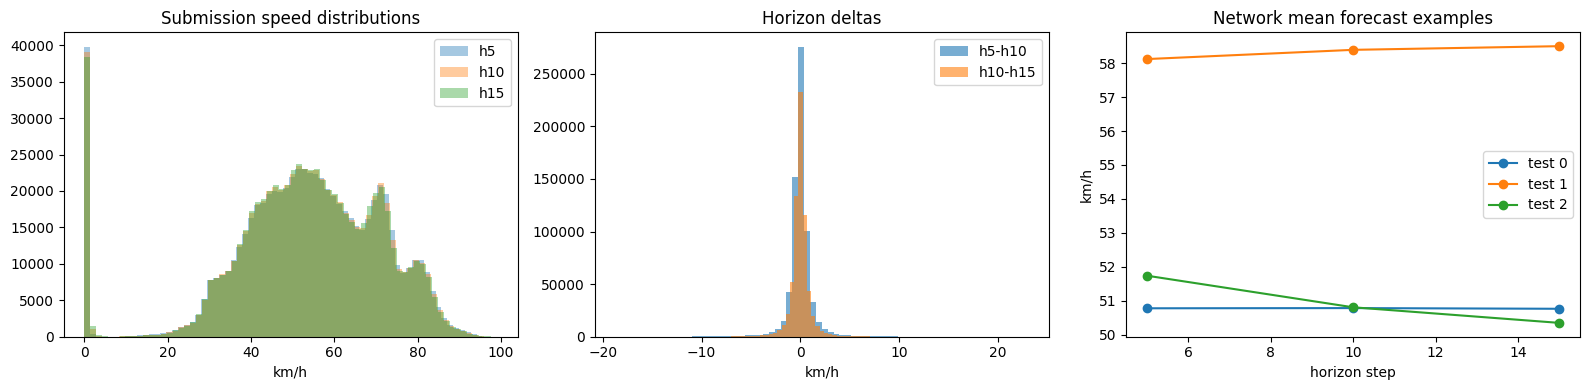

Saved: /kaggle/working/submission_v5.csv
Also saved: v5_experiment_results.csv and V5 seed checkpoints


,id,speed
0,test_00000_h5_r0,47.512218
1,test_00000_h5_r1,67.974915
2,test_00000_h5_r2,69.954597
2041197,test_00539_h15_r1257,63.277752
2041198,test_00539_h15_r1258,68.654877
2041199,test_00539_h15_r1259,0.004999


In [12]:
submission=sample_submission.copy(); flat=test_pred.transpose(0,2,1).reshape(-1)
assert len(flat)==len(submission); assert submission.id.iloc[0]=='test_00000_h5_r0'; assert submission.id.iloc[N_ROADS]=='test_00000_h10_r0'; assert submission.id.iloc[3*N_ROADS]=='test_00001_h5_r0'; assert submission.id.iloc[-1]=='test_00539_h15_r1259'
submission['speed']=flat; assert submission.speed.notna().all() and submission.speed.between(0,160).all()
submission_path=OUTPUT_DIR/'submission_v5.csv'; submission.to_csv(submission_path,index=False)

mean3=test_hist[:,-3:].mean(1); audit=[]
for i,h in enumerate(HORIZONS):
    x=test_pred[...,i]; audit.append({'horizon':f'h{h}','mean':x.mean(),'std':x.std(),'min':x.min(),'max':x.max(),'zeros':int(np.sum(x==0)),'mean_abs_vs_mean3':np.mean(np.abs(x-mean3))})
audit_df=pd.DataFrame(audit); display(audit_df.round(5)); print('Mean absolute h5-h10 / h10-h15:',float(np.mean(np.abs(test_pred[...,0]-test_pred[...,1]))),float(np.mean(np.abs(test_pred[...,1]-test_pred[...,2]))))

fig,ax=plt.subplots(1,3,figsize=(16,4))
for i,h in enumerate(HORIZONS): ax[0].hist(test_pred[...,i].ravel(),bins=70,alpha=.4,label=f'h{h}')
ax[0].set(title='Submission speed distributions',xlabel='km/h'); ax[0].legend()
ax[1].hist((test_pred[...,0]-test_pred[...,1]).ravel(),bins=70,alpha=.6,label='h5-h10'); ax[1].hist((test_pred[...,1]-test_pred[...,2]).ravel(),bins=70,alpha=.6,label='h10-h15'); ax[1].set(title='Horizon deltas',xlabel='km/h'); ax[1].legend()
sample_ids=[0,min(1,len(test_pred)-1),min(2,len(test_pred)-1)]
for s in sample_ids: ax[2].plot(HORIZONS,test_pred[s].mean(0),marker='o',label=f'test {s}')
ax[2].set(title='Network mean forecast examples',xlabel='horizon step',ylabel='km/h'); ax[2].legend(); plt.tight_layout(); plt.show()

diagnostics={'selected_config':asdict(best_config),'refit_epochs':refit_epochs,'test_block_weights':TEST_BLOCK_WEIGHTS.tolist(),'balanced_validation_mse':float(blend_balanced.mean()),'test_weighted_validation_mse':float(blend_weighted.mean()),'ensemble_weights':W.tolist(),'submission_rows':len(submission)}
(OUTPUT_DIR/'v5_diagnostics.json').write_text(json.dumps(diagnostics,indent=2))
print('Saved:',submission_path); print('Also saved: v5_experiment_results.csv and V5 seed checkpoints')
display(pd.concat([submission.head(3),submission.tail(3)]))


## 13. Deadline decision

- Main metric: inferred-test-weighted validation MSE.
- DirectLR dipakai hanya jika simplex memberi bobot positif; jika tidak, hasil otomatis kembali ke Malfa-style PCA/GNN.
- Runtime target full mode: 20–45 menit pada T4 karena hanya satu architecture, dua validation seeds, dan dua final seeds.
- Download `/kaggle/working/submission_v5.csv`, `/kaggle/working/v5_experiment_results.csv`, checkpoints, dan executed notebook.
- Submit V5 sebagai entry terpisah; jangan overwrite Malfa 37.1 atau V4.
